# Stock return prediction: development analysis

Compare four fixed controls, four Ridge models and eight LightGBM models. The completed run uses expanding monthly fits on mature observed returns. This notebook analyses all 1,536 candidate-month records; it does not train models. The training workflow and paired target comparison are separate notebooks. These are development results, not trading returns or final holdout scores.

In [1]:
from pathlib import Path
import hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'pyproject.toml').exists())
report = root / 'reports/stock_development_v1'
sha = lambda path: hashlib.sha256(path.read_bytes()).hexdigest()
manifest = json.loads((report/'export-manifest.json').read_text())
assert (report/'COMPLETE').read_text().strip() == sha(report/'export-manifest.json')
assert manifest['complete'] and not manifest['holdout_evaluated']
for name, digest in manifest['outputs_sha256'].items():
    assert sha(report/name) == digest, name
metrics = pd.read_json(report/'metrics.json')
selection = json.loads((report/'development-selection.json').read_text())
config = json.loads((report/'config.json').read_text())
uncertainty = json.loads((report/'uncertainty.json').read_text())
assert len(metrics) == 1536 and metrics.candidate_id.nunique() == 16
assert not metrics.duplicated(['candidate_id','signal_session']).any()
display(metrics.groupby(['status','fit_status']).size().rename('candidate_months').to_frame())

candidate_months
status                              fit_status                            
insufficient_resolved_cross_section fitted                              24
                                    fixed_control_no_fit                 8
valid                               fitted                            1128
                                    fixed_control_no_fit               376

## Evaluation support

All 96 scheduled development months remain in the source table. Comparisons use the same 94 mature months for every candidate. November and December 2014 outcomes mature after the selection cutoff and cannot contribute outcome values. The original archive has unverified price-adjustment and vintage semantics; the results are conditional on that source.

,mean,median,std,positive_month_fraction,months
candidate_id,,,,,
control_fixed_composite,0.023158,0.050342,0.229924,0.574468,94
control_momentum_F01,0.018317,0.045112,0.207163,0.617021,94
control_low_volatility_F09,0.009911,0.004029,0.238134,0.521277,94
lgbm_regression_l1_leaves15_iterations100,0.008557,0.012471,0.080718,0.585106,94
lgbm_regression_l1_leaves15_iterations300,0.008072,0.011000,0.074926,0.648936,94
lgbm_regression_l1_leaves7_iterations100,0.004081,0.006340,0.083326,0.574468,94
lgbm_regression_l1_leaves7_iterations300,0.003507,0.009075,0.080302,0.553191,94
lgbm_regression_l2_leaves15_iterations300,-0.003420,0.004247,0.085373,0.531915,94
lgbm_regression_l2_leaves7_iterations300,-0.007776,0.006925,0.091120,0.521277,94


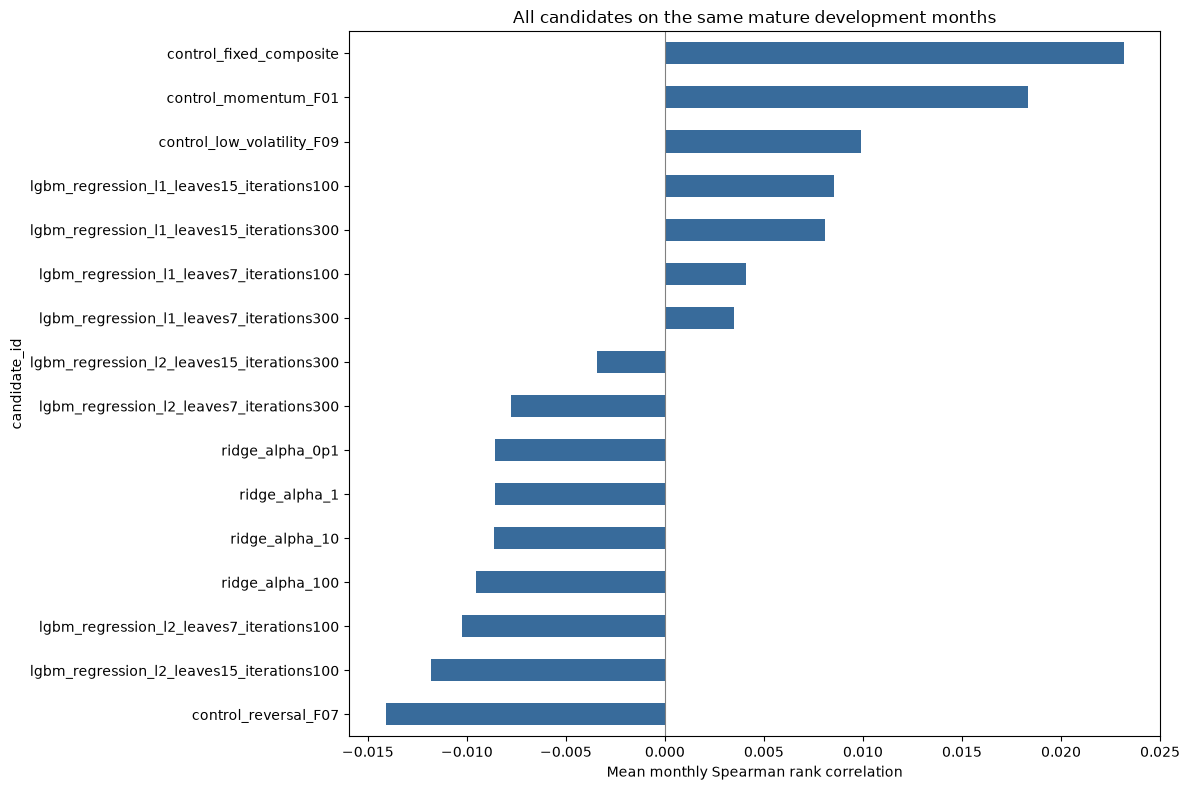

In [2]:
dates = selection['common_dates']
assert len(dates) == 94 and dates[-1] == '2014-10-31'
paired = metrics[metrics.signal_session.isin(dates)].copy()
assert len(paired) == 94*16 and paired.status.eq('valid').all()
wide = paired.pivot(index='signal_session', columns='candidate_id', values='ic').sort_index()
assert wide.notna().all().all()
summary = wide.agg(['mean','median','std']).T
summary['positive_month_fraction'] = wide.gt(0).mean()
summary['months'] = len(wide)
summary = summary.sort_values('mean', ascending=False)
expected = {row['candidate_id']: row['mean_monthly_ic'] for row in selection['candidates']}
for name, value in summary['mean'].items():
    assert np.isclose(value, expected[name], atol=1e-14)
display(summary)
summary['mean'].sort_values().plot.barh(figsize=(12,8), color='#386b9b')
plt.xlabel('Mean monthly Spearman rank correlation')
plt.axvline(0,color='gray',lw=.8)
plt.title('All candidates on the same mature development months')
plt.tight_layout(); plt.show()

## Behavior through time

The best learned candidate below is selected on this development history. Its curve is exploratory, not a separately held-out result. Cumulative IC is a diagnostic sum of correlations, not cumulative portfolio return.

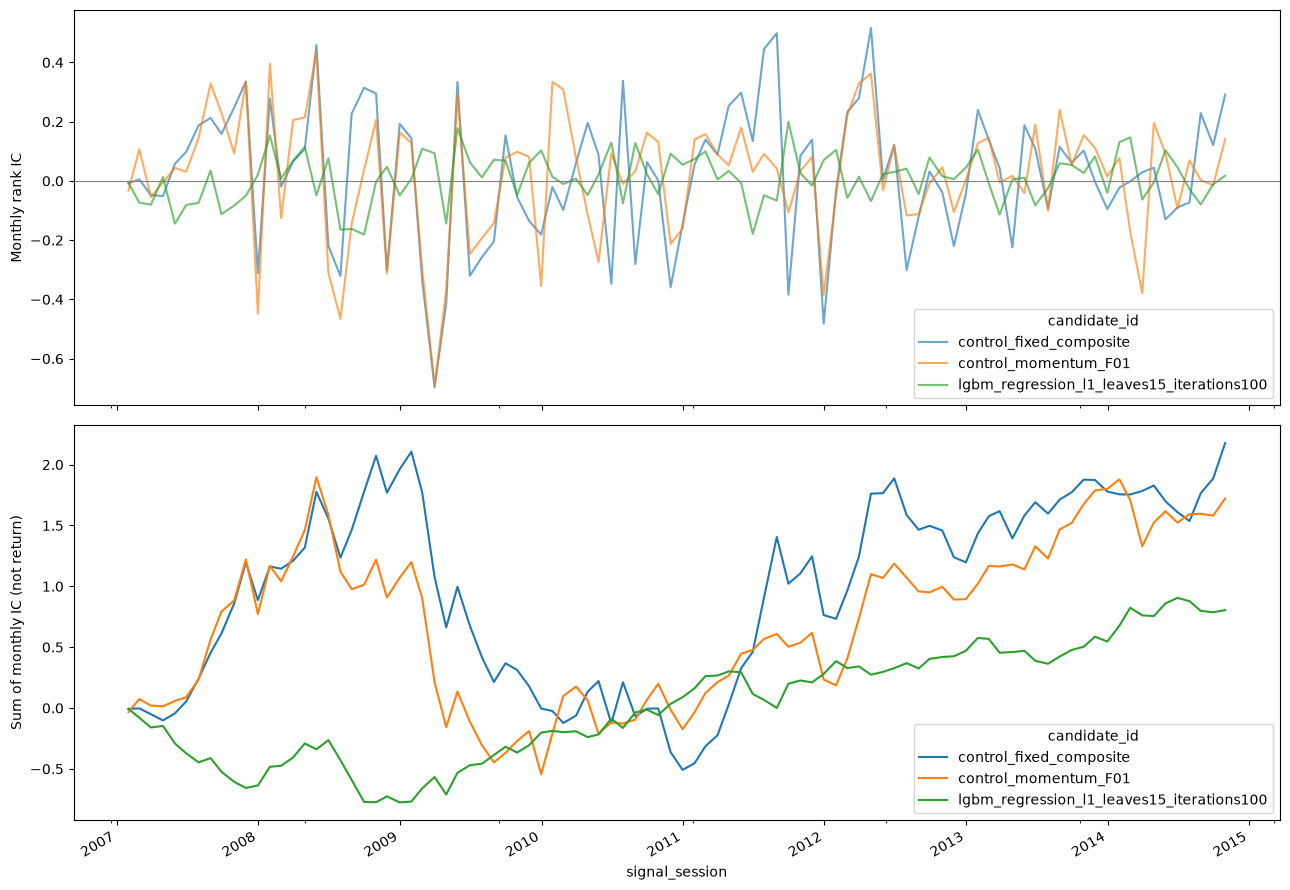

period,2007–2008,2009–2010,2011–2012,2013–2014
candidate,,,,
control_fixed_composite,0.081762,-0.102948,0.071053,0.044549
control_low_volatility_F09,0.048510,-0.088960,0.064254,0.016376
control_momentum_F01,0.044645,-0.051911,0.044538,0.037603
control_reversal_F07,-0.061638,0.019712,-0.006959,-0.006859
lgbm_regression_l1_leaves15_iterations100,-0.032308,0.036006,0.015910,0.015170
lgbm_regression_l1_leaves15_iterations300,-0.027585,0.032438,0.014377,0.013509
lgbm_regression_l1_leaves7_iterations100,-0.035330,0.028260,0.017125,0.006467
lgbm_regression_l1_leaves7_iterations300,-0.033403,0.022655,0.010124,0.015666
lgbm_regression_l2_leaves15_iterations100,-0.039486,0.018795,-0.017824,-0.008420


Development-selected learned candidate: lgbm_regression_l1_leaves15_iterations100


In [3]:
learned = [name for name in wide if not name.startswith('control_')]
best_learned = wide[learned].mean().idxmax()
shown = ['control_fixed_composite','control_momentum_F01',best_learned]
timeline = wide[shown].copy(); timeline.index = pd.to_datetime(timeline.index)
fig, axes = plt.subplots(2,1,figsize=(13,9),sharex=True)
timeline.plot(ax=axes[0],alpha=.65); axes[0].axhline(0,color='gray',lw=.8)
axes[0].set_ylabel('Monthly rank IC')
timeline.cumsum().plot(ax=axes[1])
axes[1].set_ylabel('Sum of monthly IC (not return)')
fig.tight_layout(); plt.show()
periods = ((2007,2008),(2009,2010),(2011,2012),(2013,2014))
period_rows = []
for first,last in periods:
    years = pd.to_datetime(wide.index).year
    group = wide.loc[(years>=first)&(years<=last)]
    for name in wide:
        period_rows.append({'period':f'{first}–{last}','candidate':name,
                            'months':len(group),'IC':group[name].mean()})
period_table = pd.DataFrame(period_rows)
display(period_table.pivot(index='candidate',columns='period',values='IC'))
print('Development-selected learned candidate:',best_learned)

## Paired uncertainty

Circular blocks resample whole observed months with identical indices across candidates. They generate no market prices. All 3-, 6- and 12-month block choices are shown. These exploratory intervals do not adjust for model selection.

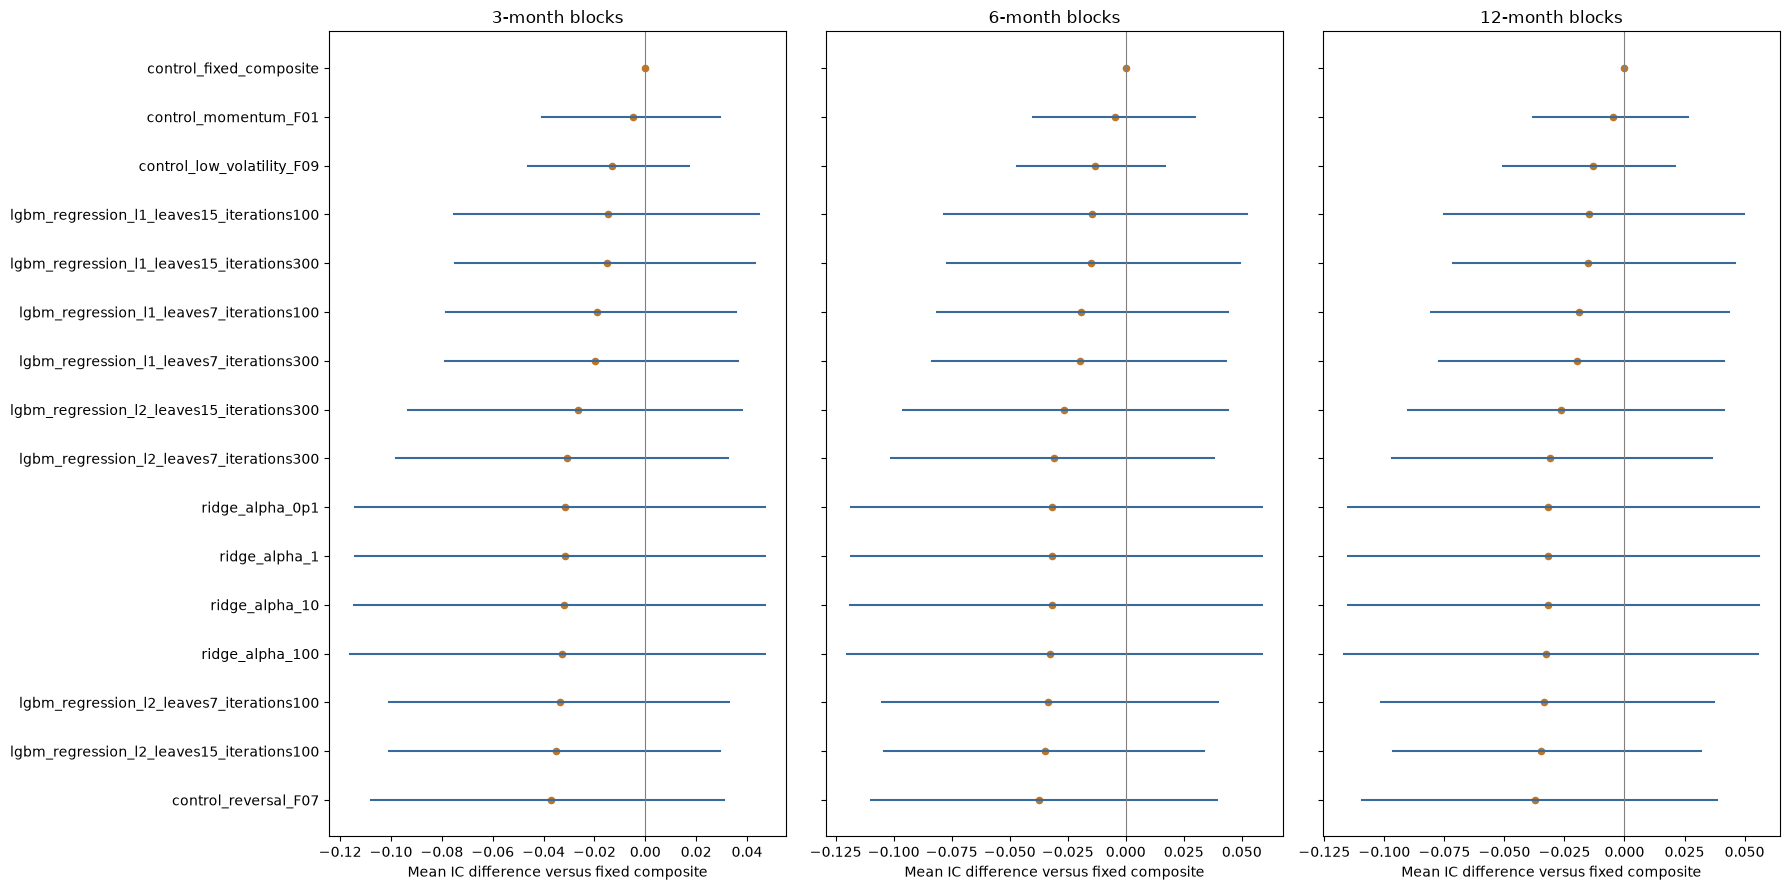

In [4]:
fig, axes = plt.subplots(1,3,figsize=(18,9),sharey=True)
order = list(summary.index[::-1])
for ax, analysis in zip(axes,uncertainty['intervals'],strict=True):
    assert analysis['months']==94 and not analysis['selection_adjusted']
    rows = {row['candidate_id']:row for row in analysis['candidates']}
    for position,name in enumerate(order):
        row=rows[name]; lo,hi=row['paired_difference_interval']
        ax.plot([lo,hi],[position,position],color='#386b9b')
        ax.scatter(row['mean_IC_difference'],position,color='#bd7628',s=20)
    ax.axvline(0,color='gray',lw=.8)
    ax.set_title(f"{analysis['block_months']}-month blocks")
    ax.set_xlabel('Mean IC difference versus fixed composite')
axes[0].set_yticks(range(len(order)),order); fig.tight_layout(); plt.show()

## Execution coverage

The separate funded backtest attempted all 16 candidates at four fee levels. Every path stopped at an unavailable or invalid owned price. These stops were checked against the original archive. No full-period stock return or Sharpe is reported; the valid prefixes are not substitutes for the requested period.

In [5]:
support_root = root/'reports/stock_economic_support_v1'
support_path = support_root/'export-manifest.json'
support = json.loads(support_path.read_bytes())
assert hashlib.sha256(support_path.read_bytes()).hexdigest() == (support_root/'COMPLETE').read_text().strip()
assert support['source_manifest_sha256'] == 'be9bbe820ffa16ec917434f8f6bb6ee18533425ec330b79f05a2e76f3ee607a7'
assert support['attempted_paths'] == support['unsupported_paths'] == 64
assert support['complete_paths'] == 0 and not support['aggregate_performance_authorized']
coverage_path = support_root/'coverage.csv'
assert hashlib.sha256(coverage_path.read_bytes()).hexdigest() == support['outputs_sha256']['coverage.csv']
coverage = pd.read_csv(coverage_path)
assert len(coverage) == 64 and coverage.candidate.nunique() == 16
assert coverage.status.eq('UNSUPPORTED_VALID_PREFIX').all()
assert not coverage.duplicated(['candidate','fee_bps']).any()
assert coverage.groupby('candidate').fee_bps.nunique().eq(4).all()
display(coverage.groupby('candidate',sort=True).agg(
    fee_scenarios=('fee_bps','size'), stopped_session=('stopped_session','first'),
    stopped_event=('stopped_event','first'),
    valid_sessions=('valid_measured_sessions','first')))
print('0 of 64 complete economic paths. Full-period performance unavailable.')

,fee_scenarios,stopped_session,stopped_event,valid_sessions
candidate,,,,
control_fixed_composite,4,2008-01-08,close,216
control_low_volatility_F09,4,2010-08-17,close,873
control_momentum_F01,4,2010-09-16,close,894
control_reversal_F07,4,2008-03-28,close,271
lgbm_regression_l1_leaves15_iterations100,4,2010-11-19,open,940
lgbm_regression_l1_leaves15_iterations300,4,2010-11-19,open,940
lgbm_regression_l1_leaves7_iterations100,4,2008-03-28,close,271
lgbm_regression_l1_leaves7_iterations300,4,2010-11-19,open,940
lgbm_regression_l2_leaves15_iterations100,4,2010-11-19,open,940


0 of 64 complete economic paths. Full-period performance unavailable.


## Interpretation

The fixed composite has the highest mean IC in this run. The learned models do not improve on it, and the paired uncertainty is wide. The controlled target comparison uses within-month ranks while preserving features, candidates and validation clocks. Its full paired results are in 08_stock_target_comparison.ipynb. The execution study above cannot establish trading profitability on the supplied stock archive; rank correlation alone does not establish it.